# 02 · EDA básico — Competencia crediticia

Versión **paso a paso** del análisis exploratorio. Cada sección responde una
pregunta sencilla y explica qué se está viendo. Para un análisis más
avanzado consulta `01_eda.ipynb`.

**Objetivo del modelo:** predecir la probabilidad de que un cliente tenga
morosidad grave (90 días o más de atraso) en los próximos 2 años.
**Métrica:** AUC-ROC.

**Qué se podrá experimentar en la competencia** (y dónde ayuda este EDA):

| Tema | Qué nos dice este EDA |
| --- | --- |
| Calidad de datos (duplicados) | Sección 1 |
| Valores faltantes y atípicos | Secciones 5 y 7 |
| Ingeniería y selección de variables | Secciones 8 y 9 |
| Algoritmos de clasificación | Sección 10 (desbalance y escalas) |
| Regularización, validación cruzada, hiperparámetros | Sección 10 |

## 0. Preparación
Cargamos las librerías y los datos. Los archivos viven en `data/raw/`
(se descargan con `PYTHONPATH=src uv run python -m etl.download`).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
train = pd.read_csv(ROOT / "data/raw/train.csv")
test = pd.read_csv(ROOT / "data/raw/test.csv")

TARGET = "SeriousDlqin2yrs"
ID = "Id"
FEATS = [c for c in train.columns if c not in (TARGET, ID)]

## 1. Ordenamiento y registros duplicados
Antes de explorar, revisamos la **calidad básica** del dataset: ¿hay
registros repetidos?

**Criterio de eliminación:** solo se elimina una fila si su `Id` está
repetido (el mismo registro cargado dos veces). Las filas con `Id` distinto se
conservan aunque su contenido sea idéntico, porque pueden ser clientes
distintos con el mismo perfil; esas solo se **reportan**.

Primero ordenamos los datos:
- Por `Id`, para tener un orden estable y reproducible.
- Por todas las variables, para que los registros iguales queden juntos y se
  puedan revisar a simple vista.

In [2]:
train = train.sort_values(ID).reset_index(drop=True)
test = test.sort_values(ID).reset_index(drop=True)

# Orden por todas las columnas: los registros idénticos quedan contiguos
train_ordenado = train.sort_values(FEATS + [TARGET], na_position="last")
train_ordenado.head()

,Id,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
94080,134366,0,0.0,21,0,0.0,0.0,1,0,0,0,0.0
95976,137103,0,0.0,21,0,0.0,0.0,1,0,0,0,0.0
32028,45616,0,0.0,21,0,0.0,1.0,1,0,0,0,0.0
85812,122511,0,0.0,21,0,0.0,1.0,2,0,0,0,0.0
45297,64512,0,0.0,21,0,0.0,240.0,1,0,0,0,0.0


Revisamos tres tipos de duplicado:

| Tipo | Definición | Acción |
| --- | --- | --- |
| Por `Id` | El mismo `Id` aparece más de una vez | **Se elimina** la copia |
| Mismo contenido | Mismas variables y mismo objetivo, distinto `Id` | Se reporta, se conserva |
| En conflicto | Mismas variables pero objetivo distinto | Se reporta, se conserva |

In [3]:
dup_id = train[ID].duplicated()
dup_exacto = train.duplicated(subset=FEATS + [TARGET], keep="first")
dup_variables = train.duplicated(subset=FEATS, keep=False)
grupos_conflicto = (
    train[dup_variables]
    .groupby(FEATS, dropna=False)[TARGET]
    .nunique()
    .gt(1)
    .sum()
)

resumen_dup = pd.DataFrame(
    {
        "registros": [
            dup_id.sum(),
            dup_exacto.sum(),
            train.duplicated(subset=FEATS + [TARGET], keep=False).sum(),
            grupos_conflicto,
        ]
    },
    index=[
        "Id repetidos",
        "Mismo contenido con distinto Id (copias)",
        "Filas involucradas en contenido repetido",
        "Grupos en conflicto (mismo perfil, objetivo distinto)",
    ],
)
resumen_dup

,registros
Id repetidos,0
Mismo contenido con distinto Id (copias),339
Filas involucradas en contenido repetido,562
"Grupos en conflicto (mismo perfil, objetivo distinto)",26


### Notificación

In [4]:
n_dup_id = int(dup_id.sum())
n_dup_contenido = int(dup_exacto.sum())
if n_dup_id > 0:
    print(f"⚠️ Hay {n_dup_id:,} Id repetidos: se eliminarán las copias.")
else:
    print("✅ No hay Id repetidos: no se elimina ninguna fila.")

if n_dup_contenido > 0:
    pct = n_dup_contenido / len(train) * 100
    print(
        f"ℹ️ Hay {n_dup_contenido:,} registros con el mismo contenido y distinto Id "
        f"({pct:.2f} % de train). Se conservan porque su Id no se repite."
    )

if grupos_conflicto > 0:
    print(
        f"ℹ️ {grupos_conflicto} grupos tienen el mismo perfil con objetivo distinto. "
        "No se eliminan (ambos resultados son reales), pero son ruido para el modelo."
    )

✅ No hay Id repetidos: no se elimina ninguna fila.
ℹ️ Hay 339 registros con el mismo contenido y distinto Id (0.32 % de train). Se conservan porque su Id no se repite.
ℹ️ 26 grupos tienen el mismo perfil con objetivo distinto. No se eliminan (ambos resultados son reales), pero son ruido para el modelo.


In [5]:
# Ejemplos: registros duplicados vistos juntos gracias al ordenamiento
mascara = train_ordenado.duplicated(subset=FEATS + [TARGET], keep=False)
train_ordenado[mascara].head(10)

,Id,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
94080,134366,0,0.0,21,0,0.0,0.0,1,0,0,0,0.0
95976,137103,0,0.0,21,0,0.0,0.0,1,0,0,0,0.0
18011,25633,0,0.0,21,0,0.0,820.0,2,0,0,0,0.0
58645,83553,0,0.0,21,0,0.0,820.0,2,0,0,0,0.0
30887,44007,0,0.0,22,0,0.0,0.0,1,0,0,0,0.0
38319,54654,0,0.0,22,0,0.0,0.0,1,0,0,0,0.0
18901,26907,0,0.0,22,0,0.0,820.0,2,0,0,0,0.0
62910,89634,0,0.0,22,0,0.0,820.0,2,0,0,0,0.0
79224,113076,0,0.0,22,0,0.0,820.0,2,0,0,0,0.0
82871,118284,0,0.0,22,0,0.0,820.0,2,0,0,0,0.0


In [6]:
# ¿Cómo son los duplicados frente al total?
filas_dup = train.duplicated(subset=FEATS + [TARGET], keep=False)
pd.DataFrame(
    {
        "duplicados": [
            train.loc[filas_dup, TARGET].mean(),
            train.loc[filas_dup, "MonthlyIncome"].isna().mean(),
            train.loc[filas_dup, "age"].median(),
        ],
        "todo train": [
            train[TARGET].mean(),
            train["MonthlyIncome"].isna().mean(),
            train["age"].median(),
        ],
    },
    index=["tasa de morosidad", "proporción sin ingreso", "edad mediana"],
).round(3)

,duplicados,todo train
tasa de morosidad,0.037,0.067
proporción sin ingreso,0.854,0.198
edad mediana,49.500,52.000


**Lectura:** los duplicados son, en su mayoría, perfiles "delgados": sin
ingreso reportado y con casi todas las variables en cero. Es posible que
algunos sean personas distintas con el mismo perfil, pero como tienen
exactamente la misma información y el mismo resultado, en el modelado pesan
doble. Como su `Id` es distinto, **se conservan**. Si más adelante se quiere
probar su efecto, se puede comparar el AUC con y sin ellos en la validación
cruzada.

### Limpieza y cifras de control
Eliminamos solo las filas con `Id` repetido (se conserva la primera) y
verificamos con cifras de control que se quitó exactamente lo esperado.

In [7]:
filas_antes = len(train)
tasa_antes = train[TARGET].mean()

train = train.drop_duplicates(subset=ID, keep="first").reset_index(drop=True)

filas_despues = len(train)
tasa_despues = train[TARGET].mean()
cifras_control = pd.DataFrame(
    {
        "filas": [filas_antes, filas_despues, filas_despues - filas_antes],
        "tasa de morosidad": [tasa_antes, tasa_despues, tasa_despues - tasa_antes],
    },
    index=["antes", "después", "diferencia"],
)
display(cifras_control.style.format({"tasa de morosidad": "{:.4f}"}))

# Reglas de calidad (DQ): si alguna falla, el notebook se detiene
assert filas_antes - filas_despues == n_dup_id, "Se eliminaron filas de más o de menos"
assert train[ID].is_unique, "Quedan Id repetidos"
print(f"✅ Dataset listo: {filas_despues:,} filas ({filas_antes - filas_despues} eliminadas).")

,filas,tasa de morosidad
antes,105000,0.0668
después,105000,0.0668
diferencia,0,0.0000


✅ Dataset listo: 105,000 filas (0 eliminadas).


### ¿Y en `test`?

In [8]:
n_dup_test = int(test.duplicated(subset=FEATS).sum())
print(f"Registros de test con perfil repetido: {n_dup_test}")
print("ℹ️ En test NO se elimina nada: la competencia pide una predicción por cada Id.")

Registros de test con perfil repetido: 80
ℹ️ En test NO se elimina nada: la competencia pide una predicción por cada Id.


**A partir de aquí, todo el análisis usa `train` sin `Id` repetidos.**

## 2. Diccionario de variables
Qué significa cada columna. Es la base para interpretar todo lo demás.

In [9]:
DICCIONARIO = {
    "SeriousDlqin2yrs": "OBJETIVO. 1 = morosidad grave (90+ días) en 2 años; 0 = no.",
    "RevolvingUtilizationOfUnsecuredLines": "Saldo en tarjetas y líneas de crédito / límite total. Debería estar entre 0 y 1.",
    "age": "Edad del cliente en años.",
    "NumberOfTime30-59DaysPastDueNotWorse": "Veces con atraso de 30 a 59 días (sin llegar a peor).",
    "DebtRatio": "Pagos mensuales de deuda / ingreso mensual bruto.",
    "MonthlyIncome": "Ingreso mensual.",
    "NumberOfOpenCreditLinesAndLoans": "Número de créditos y líneas abiertas.",
    "NumberOfTimes90DaysLate": "Veces con atraso de 90 días o más.",
    "NumberRealEstateLoansOrLines": "Número de créditos hipotecarios o inmobiliarios.",
    "NumberOfTime60-89DaysPastDueNotWorse": "Veces con atraso de 60 a 89 días (sin llegar a peor).",
    "NumberOfDependents": "Número de dependientes económicos (sin contar al cliente).",
}
pd.Series(DICCIONARIO, name="descripción").to_frame()

,descripción
SeriousDlqin2yrs,OBJETIVO. 1 = morosidad grave (90+ días) en 2 ...
RevolvingUtilizationOfUnsecuredLines,Saldo en tarjetas y líneas de crédito / límite...
age,Edad del cliente en años.
NumberOfTime30-59DaysPastDueNotWorse,Veces con atraso de 30 a 59 días (sin llegar a...
DebtRatio,Pagos mensuales de deuda / ingreso mensual bruto.
MonthlyIncome,Ingreso mensual.
NumberOfOpenCreditLinesAndLoans,Número de créditos y líneas abiertas.
NumberOfTimes90DaysLate,Veces con atraso de 90 días o más.
NumberRealEstateLoansOrLines,Número de créditos hipotecarios o inmobiliarios.
NumberOfTime60-89DaysPastDueNotWorse,Veces con atraso de 60 a 89 días (sin llegar a...


## 3. Tamaño y primeras filas
¿Cuántas filas y columnas hay? ¿Cómo se ve un registro?

In [10]:
print(f"train: {train.shape[0]:,} filas x {train.shape[1]} columnas")
print(f"test : {test.shape[0]:,} filas x {test.shape[1]} columnas")
print("Columnas que están en train pero no en test:", set(train.columns) - set(test.columns))
train.head()

train: 105,000 filas x 12 columnas
test : 45,000 filas x 11 columnas
Columnas que están en train pero no en test: {'SeriousDlqin2yrs'}


,Id,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
1,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
2,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
3,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0
4,7,0,0.305682,57,0,5710.000000,NaN,8,0,3,0,0.0


**Lectura:** `test` no trae la columna objetivo; es lo que el modelo debe
predecir. Solo podemos medir qué tan bien funciona con validación sobre
`train`.

## 4. Variable objetivo
¿Qué proporción de clientes cae en morosidad grave?

,clientes,porcentaje
SeriousDlqin2yrs,,
0,97982,93.32
1,7018,6.68


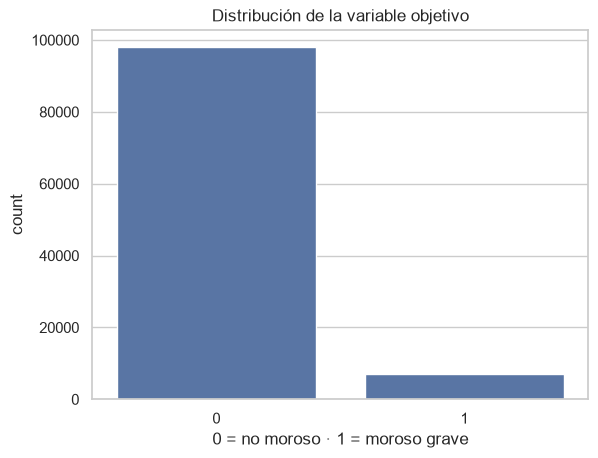

In [11]:
conteo = train[TARGET].value_counts().rename("clientes").to_frame()
conteo["porcentaje"] = (train[TARGET].value_counts(normalize=True) * 100).round(2)
display(conteo)

ax = sns.countplot(data=train, x=TARGET)
ax.set_title("Distribución de la variable objetivo")
ax.set_xlabel("0 = no moroso · 1 = moroso grave")
plt.show()

**Lectura:** la clase `1` es muy minoritaria (**datos desbalanceados**).
Consecuencias para el modelado:
- Accuracy no sirve: predecir siempre `0` ya daría ~93 %. Por eso la métrica es AUC-ROC.
- Conviene usar **validación cruzada estratificada** (mantiene la proporción en cada partición).
- Algunos modelos aceptan pesos de clase (`class_weight`).

## 5. Valores faltantes
¿Qué columnas tienen datos vacíos y cuántos?

In [12]:
faltantes = pd.DataFrame(
    {
        "n_faltantes": train[FEATS].isna().sum(),
        "% train": (train[FEATS].isna().mean() * 100).round(2),
        "% test": (test[FEATS].isna().mean() * 100).round(2),
    }
)
faltantes[faltantes["n_faltantes"] > 0]

,n_faltantes,% train,% test
MonthlyIncome,20828,19.84,19.78
NumberOfDependents,2771,2.64,2.56


In [13]:
# ¿Quien no reporta ingreso es más o menos moroso?
(
    train.groupby(train["MonthlyIncome"].isna())[TARGET]
    .agg(clientes="count", tasa_morosidad="mean")
    .rename_axis("ingreso_faltante")
    .round(4)
)

,clientes,tasa_morosidad
ingreso_faltante,,
False,84172,0.0695
True,20828,0.0561


**Lectura:** faltan datos en `MonthlyIncome` y en `NumberOfDependents`. El
patrón de faltantes es parecido en `train` y `test`.
Si la tasa de morosidad cambia cuando falta el ingreso, el hecho de que falte
**ya es información**: una opción es crear una columna indicadora
(`ingreso_faltante`) además de imputar (por ejemplo con la mediana).

## 6. Estadísticos descriptivos
Mínimo, máximo, media y percentiles de cada variable numérica.

In [14]:
train[FEATS].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T.round(2)

,count,mean,std,min,1%,25%,50%,75%,99%,max
RevolvingUtilizationOfUnsecuredLines,105000.0,6.41,273.64,0.0,0.0,0.03,0.15,0.56,1.09,50708.0
age,105000.0,52.29,14.78,0.0,24.0,41.00,52.00,63.00,87.00,103.0
NumberOfTime30-59DaysPastDueNotWorse,105000.0,0.43,4.29,0.0,0.0,0.00,0.00,0.00,4.00,98.0
DebtRatio,105000.0,358.33,2318.26,0.0,0.0,0.17,0.37,0.87,5011.01,329664.0
MonthlyIncome,84172.0,6645.49,15507.79,0.0,0.0,3400.00,5400.00,8208.00,25000.00,3008750.0
NumberOfOpenCreditLinesAndLoans,105000.0,8.44,5.13,0.0,0.0,5.00,8.00,11.00,24.00,58.0
NumberOfTimes90DaysLate,105000.0,0.27,4.26,0.0,0.0,0.00,0.00,0.00,3.00,98.0
NumberRealEstateLoansOrLines,105000.0,1.02,1.14,0.0,0.0,0.00,1.00,2.00,4.00,54.0
NumberOfTime60-89DaysPastDueNotWorse,105000.0,0.25,4.25,0.0,0.0,0.00,0.00,0.00,2.00,98.0
NumberOfDependents,102229.0,0.76,1.11,0.0,0.0,0.00,0.00,1.00,4.00,13.0


**Cómo leer la tabla:** compara `50%` (mediana) con `mean` y con `max`.
- Si `max` es enorme frente al `99%`, hay **valores atípicos** (outliers).
- Si `mean` está muy lejos de la mediana, la distribución tiene cola larga.

Cosas que suelen llamar la atención aquí: `age` con mínimo 0,
`RevolvingUtilizationOfUnsecuredLines` muy por encima de 1 y las variables de
atraso con valores 96 o 98 (códigos especiales, no conteos reales).

## 7. Valores atípicos
Revisamos tres casos concretos.

In [15]:
print("Edad menor a 18:", (train["age"] < 18).sum())
print("Edad mayor a 90:", (train["age"] > 90).sum())
print("Utilización de líneas > 1:", (train["RevolvingUtilizationOfUnsecuredLines"] > 1).sum())
print("DebtRatio > 10:", (train["DebtRatio"] > 10).sum())

LATE = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
]
print("\nValores más altos en variables de atraso:")
for c in LATE:
    print(f"  {c}: {sorted(train[c].unique())[-4:]}")

Edad menor a 18: 1
Edad mayor a 90: 336
Utilización de líneas > 1: 2316
DebtRatio > 10: 20203

Valores más altos en variables de atraso:
  NumberOfTime30-59DaysPastDueNotWorse: [np.int64(12), np.int64(13), np.int64(96), np.int64(98)]
  NumberOfTime60-89DaysPastDueNotWorse: [np.int64(9), np.int64(11), np.int64(96), np.int64(98)]
  NumberOfTimes90DaysLate: [np.int64(14), np.int64(15), np.int64(96), np.int64(98)]


In [16]:
# Los valores 96 y 98 parecen códigos especiales: ¿cómo se comportan?
codigo = (train[LATE] >= 96).any(axis=1)
print("Filas con código 96/98:", codigo.sum())
print("Tasa de morosidad CON código   :", round(train.loc[codigo, TARGET].mean(), 4))
print("Tasa de morosidad SIN código   :", round(train.loc[~codigo, TARGET].mean(), 4))

Filas con código 96/98: 197
Tasa de morosidad CON código   : 0.5685
Tasa de morosidad SIN código   : 0.0659


**Lectura:** los 96/98 no son 96 atrasos reales: son marcas especiales y
además están asociadas a una tasa de morosidad muy distinta. Opciones:
tratarlos como categoría aparte, ponerlos en `NaN` y crear un indicador, o
recortar (*winsorizar*) el valor. Edades de 0 y razones de utilización o
deuda extremas se pueden recortar a un percentil alto (p. ej. 99).

## 8. Distribución de cada variable
Histogramas recortados al percentil 99 para que las colas extremas no
aplasten el gráfico.

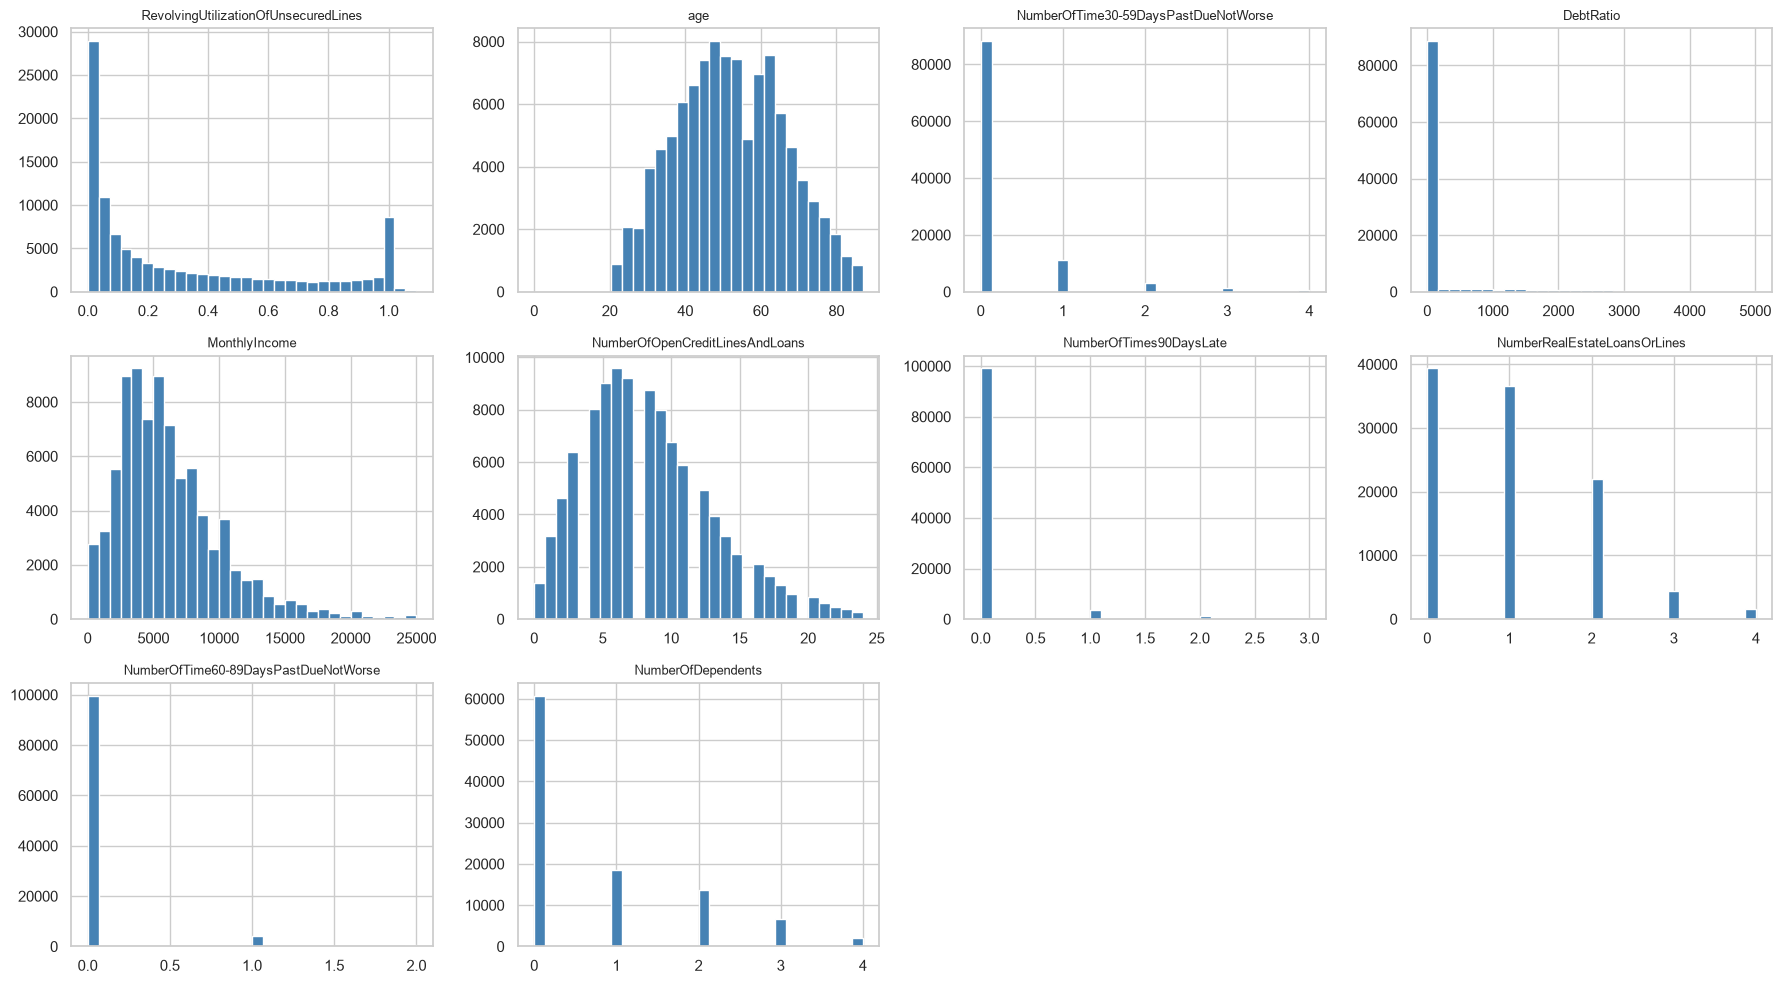

In [17]:
fig, axes = plt.subplots(3, 4, figsize=(18, 10))
for ax, col in zip(axes.ravel(), FEATS):
    serie = train[col].dropna()
    serie = serie[serie <= serie.quantile(0.99)]
    ax.hist(serie, bins=30, color="steelblue")
    ax.set_title(col, fontsize=9)
for ax in axes.ravel()[len(FEATS):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

**Lectura:** la mayoría de las variables son muy asimétricas (muchos valores
pequeños y pocos grandes). Para modelos lineales ayuda aplicar `log1p` o
discretizar; los modelos de árboles no lo necesitan.

## 9. Relación de cada variable con el objetivo
¿Qué variables parecen separar a morosos de no morosos?

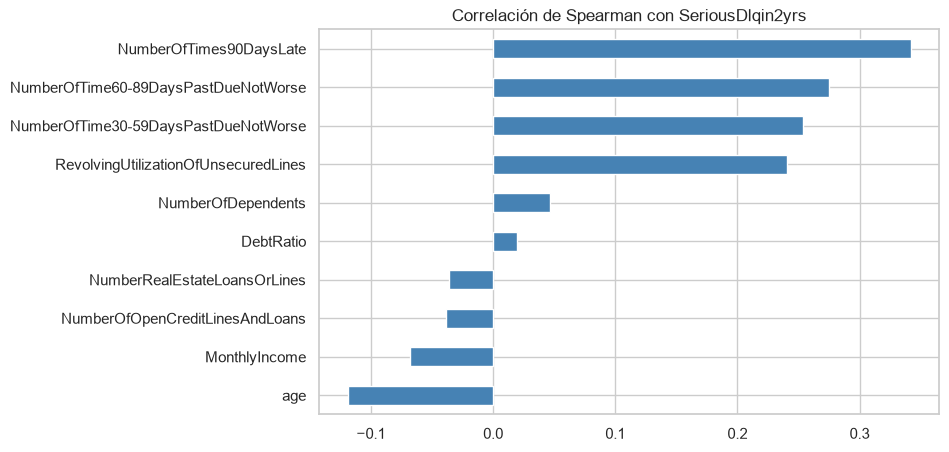

In [18]:
corr = train[FEATS + [TARGET]].corr(method="spearman")[TARGET].drop(TARGET)
corr.sort_values().plot.barh(figsize=(8, 5), color="steelblue")
plt.title("Correlación de Spearman con SeriousDlqin2yrs")
plt.show()

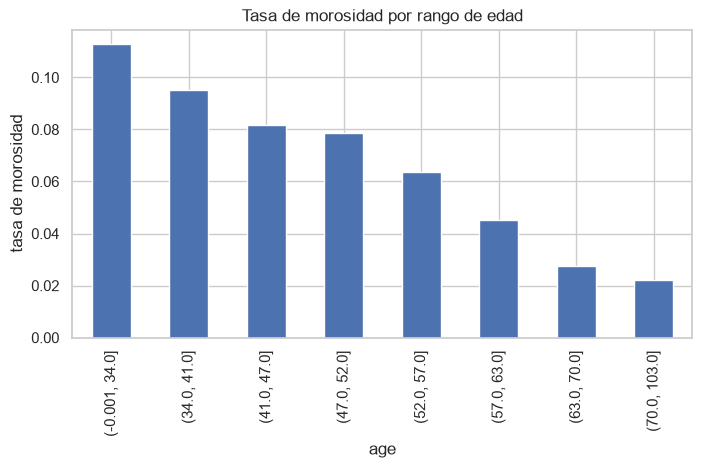

In [19]:
# Tasa de morosidad por rangos de edad (cuantiles)
rangos = pd.qcut(train["age"], 8)
train.groupby(rangos, observed=True)[TARGET].mean().plot(kind="bar", figsize=(8, 4))
plt.title("Tasa de morosidad por rango de edad")
plt.ylabel("tasa de morosidad")
plt.show()

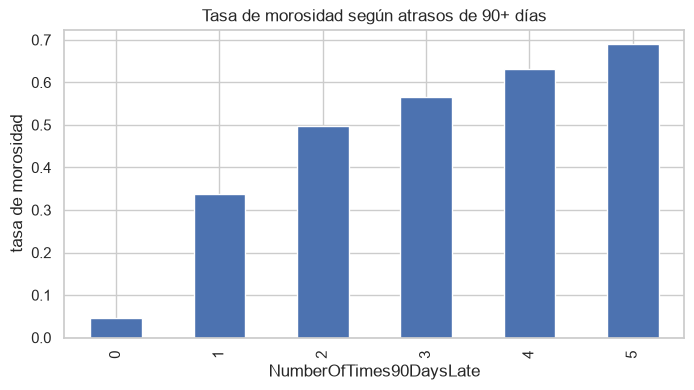

In [20]:
# Tasa de morosidad según número de atrasos de 90+ días (0 a 5)
t = train[train["NumberOfTimes90DaysLate"] <= 5]
t.groupby("NumberOfTimes90DaysLate")[TARGET].mean().plot(kind="bar", figsize=(8, 4))
plt.title("Tasa de morosidad según atrasos de 90+ días")
plt.ylabel("tasa de morosidad")
plt.show()

**Lectura:** las variables de atraso previo son las más relacionadas con la
morosidad futura, seguidas de la utilización de líneas de crédito
(`RevolvingUtilizationOfUnsecuredLines`). La edad tiene relación inversa (a
mayor edad, menor riesgo). Ideas de **ingeniería de variables** que salen de aquí:
- Suma total de atrasos (30-59 + 60-89 + 90+).
- Indicador de "tuvo algún atraso".
- Ingreso por dependiente (`MonthlyIncome / (NumberOfDependents + 1)`).
- Indicadores de faltante y de códigos 96/98.

## 10. Resumen y siguientes pasos

| Hallazgo | Qué hacer después |
| --- | --- |
| Sin `Id` repetidos; 339 filas con mismo contenido y distinto `Id` | No se elimina nada; probar su efecto en validación cruzada |
| Perfiles idénticos con objetivo distinto | Se conservan; son ruido irreducible |
| Clase positiva muy minoritaria | Validación cruzada estratificada, AUC-ROC, `class_weight` |
| Faltantes en ingreso y dependientes | Imputar (mediana) + columna indicadora |
| Códigos 96/98 en variables de atraso | Tratarlos aparte (NaN + indicador) |
| Edad 0, utilización y DebtRatio extremos | Recortar a percentil alto o limpiar |
| Variables muy asimétricas | `log1p` para modelos lineales; árboles no lo requieren |
| Atrasos previos son los más predictivos | Crear variables agregadas de atrasos |

**Plan de experimentos sugerido:**
1. Línea base: regresión logística con regularización (L1/L2) sobre datos limpios y escalados.
2. Modelos de árboles: Random Forest y Gradient Boosting (manejan asimetría y no linealidad).
3. Validación cruzada estratificada de 5 particiones, medida en AUC-ROC.
4. Selección de hiperparámetros con búsqueda (`GridSearchCV` / `RandomizedSearchCV`).
5. Comparar el efecto de cada decisión de limpieza y de variables nuevas.

**Importante:** las transformaciones (medianas, escalado) se ajustan solo con
los datos de entrenamiento de cada partición, para evitar fuga de datos.